# TRUSTSR Lab 01.7 — Blind Missing-Dependency Detection

**Status:** Synthetic simulation / research prototype  
**Version:** 0.1.0

## Research question
How do dependency-recovery policies behave when they **do not receive the true list of missing edges**?

Lab 01.6's uncertainty policy was given the exact removed-edge list by the experiment controller. That is an oracle signal, not a missing-edge detector. This lab removes that advantage and compares:
1. **Observed reachability:** quarantine only states reachable from the poison source in the observed graph.
2. **Heuristic suspicion:** infer suspicious nodes from observed graph structure and a configurable risk rule, then quarantine those nodes and their observed descendants.
3. **Oracle upper bound (reference only):** use the true missing-edge list. This is not an implementable detector; it is retained only to show an optimistic upper bound.

## Heuristic under test
For every node except the poison source, calculate its **incoming-edge deficit**:
`deficit(v) = max(0, expected_in_degree(v) - observed_in_degree(v))`.
In a real system, expected in-degree is generally unknown. To make the experiment explicit and reproducible, this synthetic benchmark gives the detector a separate **expected-degree metadata field** with controlled noise. It does **not** give it the missing-edge identities. This is still a strong information assumption and must be disclosed.

A node is flagged when its deficit meets a configurable threshold. The detector quarantines flagged nodes and their observed descendants, plus the observed reachability quarantine from the poison source.

## Important limitation
This is a synthetic benchmark of a toy detector under an explicit metadata assumption. It does not prove real-world missing-edge detection, causal correctness, or production recovery. The oracle upper bound must never be presented as a deployable strategy.

## 1. Install dependencies and set reproducible parameters

In [1]:
%pip -q install networkx pandas numpy matplotlib

In [2]:
import sys, platform
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

SEED = 20261011
rng = np.random.default_rng(SEED)
N_TRIALS = 300
N_NODES = 24
EDGE_PROBABILITY = 0.13
EDGE_REMOVAL_PROBABILITY = 0.15
DEGREE_METADATA_NOISE = 0.10
DEFICIT_THRESHOLD = 1

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("NetworkX:", nx.__version__, "| Pandas:", pd.__version__, "| NumPy:", np.__version__)
print("Seed:", SEED, "| Trials:", N_TRIALS, "| Nodes/graph:", N_NODES)
print("Expected-degree metadata noise:", DEGREE_METADATA_NOISE)
print("Deficit threshold:", DEFICIT_THRESHOLD)
print("Execution UTC:", datetime.now(timezone.utc).isoformat())
print("Evidence type: synthetic simulation only")

Python: 3.12.3
Platform: Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NetworkX: 3.6.1 | Pandas: 3.0.2 | NumPy: 2.4.4
Seed: 20261011 | Trials: 300 | Nodes/graph: 24
Expected-degree metadata noise: 0.1
Deficit threshold: 1
Execution UTC: 2026-10-11T10:26:27.243841+00:00
Evidence type: synthetic simulation only


## 2. Generate ground-truth graphs and blind observations

In [3]:
def generate_graph(rng, n_nodes=N_NODES, edge_p=EDGE_PROBABILITY):
    G = nx.DiGraph()
    G.add_nodes_from(range(n_nodes))
    for u in range(n_nodes):
        for v in range(u + 1, n_nodes):
            if rng.random() < edge_p:
                G.add_edge(u, v)
    if G.out_degree(0) == 0:
        G.add_edge(0, int(rng.integers(1, n_nodes)))
    return G

def hide_edges(G_truth, rng, removal_p=EDGE_REMOVAL_PROBABILITY):
    G_obs = G_truth.copy()
    removed = []
    for edge in list(G_truth.edges()):
        if rng.random() < removal_p:
            G_obs.remove_edge(*edge)
            removed.append(edge)
    return G_obs, removed

def observed_descendants(G, nodes):
    result = set(nodes)
    for node in list(nodes):
        result.update(nx.descendants(G, node))
    return result

def build_expected_degree_metadata(G_truth, rng, noise_rate=DEGREE_METADATA_NOISE):
    # Metadata is an independent noisy count, not a list of missing edge identities.
    metadata = {}
    for node in G_truth.nodes():
        true_in = G_truth.in_degree(node)
        if rng.random() < noise_rate:
            # Corrupt the expected count by +/-1, clipped at zero.
            true_in = max(0, true_in + int(rng.choice([-1, 1])))
        metadata[node] = true_in
    return metadata

def blind_heuristic_quarantine(G_obs, expected_in_degree, source=0, threshold=DEFICIT_THRESHOLD):
    base = set(nx.descendants(G_obs, source))
    deficits = {
        node: max(0, expected_in_degree[node] - G_obs.in_degree(node))
        for node in G_obs.nodes()
    }
    flagged = {node for node, deficit in deficits.items()
               if node != source and deficit >= threshold}
    # Flagged nodes and their observed descendants are quarantined.
    q = base | observed_descendants(G_obs, flagged)
    q.discard(source)
    return q, flagged, deficits

def oracle_quarantine(G_obs, removed_edges, source=0):
    # Upper bound only: has access to actual removed-edge identities.
    q = set(nx.descendants(G_obs, source))
    endpoints = {v for _, v in removed_edges}
    q |= observed_descendants(G_obs, endpoints)
    q.discard(source)
    return q

print("Graph generation and blind heuristic defined.")
print("The heuristic sees expected in-degree counts only—not removed-edge identities.")

Graph generation and blind heuristic defined.
The heuristic sees expected in-degree counts only—not removed-edge identities.


## 3. Run the blind-detection experiment

In [4]:
trial_rows = []
node_rows = []
for trial_id in range(N_TRIALS):
    G_truth = generate_graph(rng)
    G_obs, removed_edges = hide_edges(G_truth, rng)
    affected = set(nx.descendants(G_truth, 0))
    if not affected:
        continue
    unaffected = set(G_truth.nodes()) - affected - {0}
    expected_in = build_expected_degree_metadata(G_truth, rng)

    baseline_q = set(nx.descendants(G_obs, 0))
    heuristic_q, flagged, deficits = blind_heuristic_quarantine(
        G_obs, expected_in, source=0, threshold=DEFICIT_THRESHOLD
    )
    oracle_q = oracle_quarantine(G_obs, removed_edges, source=0)

    strategies = [
        ("Observed reachability", baseline_q, set()),
        ("Blind degree-deficit heuristic", heuristic_q, flagged),
        ("Oracle upper bound (not deployable)", oracle_q, {v for _, v in removed_edges}),
    ]
    for name, quarantine, signals in strategies:
        fn = affected - quarantine
        over = unaffected & quarantine
        trial_rows.append({
            "trial_id": trial_id,
            "strategy": name,
            "affected_count": len(affected),
            "false_negative_count": len(fn),
            "false_negative_rate": len(fn)/len(affected),
            "quarantined_count": len(quarantine),
            "over_quarantined_unaffected_count": len(over),
            "unaffected_preserved_count": len(unaffected - quarantine),
            "unaffected_preservation_rate": len(unaffected - quarantine)/len(unaffected) if unaffected else np.nan,
            "missing_edge_count": len(removed_edges),
            "flagged_node_count": len(signals),
            "metadata_noise_rate": DEGREE_METADATA_NOISE,
        })
    for node in sorted(G_truth.nodes()):
        node_rows.append({
            "trial_id": trial_id,
            "node_id": node,
            "ground_truth_affected": node in affected,
            "observed_in_degree": G_obs.in_degree(node),
            "expected_in_degree_metadata": expected_in[node],
            "degree_deficit": deficits.get(node, max(0, expected_in[node] - G_obs.in_degree(node))),
            "blind_heuristic_flagged": node in flagged,
            "blind_heuristic_quarantined": node in heuristic_q,
        })

results_df = pd.DataFrame(trial_rows)
node_df = pd.DataFrame(node_rows)
print("Evaluated trials:", results_df["trial_id"].nunique())
print("Strategy rows:", len(results_df))
display(results_df.head(9))

Evaluated trials: 300
Strategy rows: 900


   trial_id                             strategy  affected_count  false_negative_count  false_negative_rate  quarantined_count  over_quarantined_unaffected_count  unaffected_preserved_count  \
0         0                Observed reachability              15                     0                  0.0                 15                                  0                           8   
1         0       Blind degree-deficit heuristic              15                     0                  0.0                 15                                  0                           8   
2         0  Oracle upper bound (not deployable)              15                     0                  0.0                 15                                  0                           8   
3         1                Observed reachability              10                     0                  0.0                 10                                  0                          13   
4         1       Blind degree-defi

## 4. Aggregate metrics — detection versus cost

In [5]:
summary = results_df.groupby("strategy", as_index=False).agg(
    trials=("trial_id", "count"),
    mean_false_negative_rate=("false_negative_rate", "mean"),
    median_false_negative_rate=("false_negative_rate", "median"),
    mean_quarantined_count=("quarantined_count", "mean"),
    mean_over_quarantined_unaffected=("over_quarantined_unaffected_count", "mean"),
    mean_unaffected_preservation_rate=("unaffected_preservation_rate", "mean"),
    mean_flagged_node_count=("flagged_node_count", "mean"),
)
display(summary)
print("Interpretation must consider both missed contamination and quarantine cost.")

                              strategy  trials  mean_false_negative_rate  median_false_negative_rate  mean_quarantined_count  mean_over_quarantined_unaffected  mean_unaffected_preservation_rate  \
0       Blind degree-deficit heuristic     300                  0.005129                    0.000000               12.486667                              3.72                           0.759824   
1                Observed reachability     300                  0.188518                    0.090909                7.083333                              0.00                           1.000000   
2  Oracle upper bound (not deployable)     300                  0.000000                    0.000000               11.586667                              2.77                           0.824034   

   mean_flagged_node_count  
0                     5.42  
1                     0.00  
2                     4.70  

Interpretation must consider both missed contamination and quarantine cost.


## 5. Plot false-negative rate and quarantine overhead

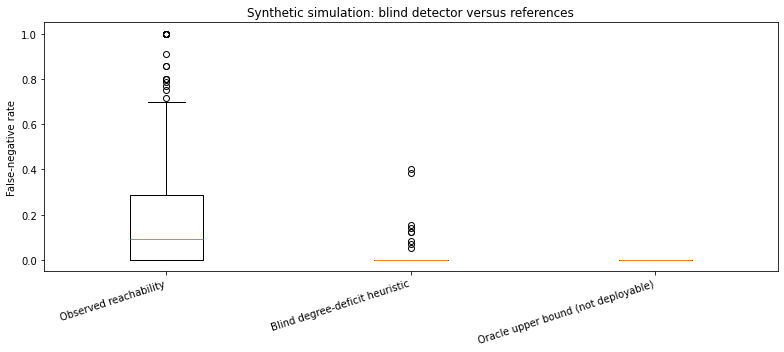

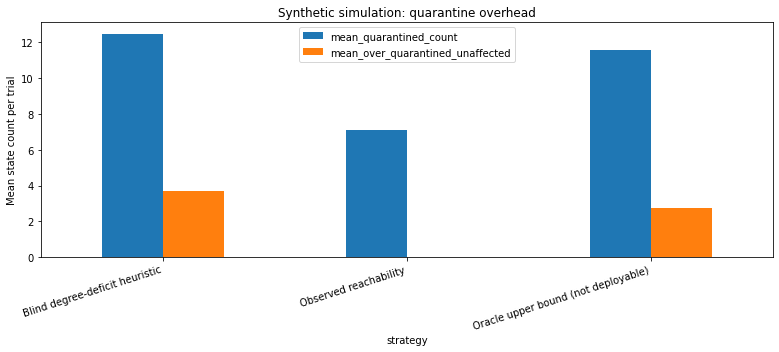

In [6]:
strategy_order = list(results_df["strategy"].drop_duplicates())
data = [results_df.loc[results_df.strategy == s, "false_negative_rate"].values for s in strategy_order]
plt.figure(figsize=(11, 5))
plt.boxplot(data, tick_labels=strategy_order)
plt.ylabel("False-negative rate")
plt.title("Synthetic simulation: blind detector versus references")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

cost = summary.set_index("strategy")[["mean_quarantined_count", "mean_over_quarantined_unaffected"]]
ax = cost.plot(kind="bar", figsize=(11, 5))
ax.set_ylabel("Mean state count per trial")
ax.set_title("Synthetic simulation: quarantine overhead")
plt.xticks(rotation=18, ha="right")
plt.tight_layout()
plt.show()

## 6. Inspect worst cases for the blind heuristic

In [7]:
heuristic_trials = results_df[results_df.strategy == "Blind degree-deficit heuristic"].sort_values(
    ["false_negative_count", "over_quarantined_unaffected_count"], ascending=[False, False]
)
display(heuristic_trials.head(10))
print("These are worst cases under this generated graph distribution and metadata assumption.")
print("They are not evidence that the heuristic works on real dependency graphs.")

     trial_id                        strategy  affected_count  false_negative_count  false_negative_rate  quarantined_count  over_quarantined_unaffected_count  unaffected_preserved_count  \
496       165  Blind degree-deficit heuristic              13                     5             0.384615                 10                                  2                           8   
664       221  Blind degree-deficit heuristic               5                     2             0.400000                  5                                  2                          16   
193        64  Blind degree-deficit heuristic              13                     2             0.153846                 12                                  1                           9   
115        38  Blind degree-deficit heuristic              14                     1             0.071429                 17                                  4                           5   
94         31  Blind degree-deficit heuristic     

These are worst cases under this generated graph distribution and metadata assumption.
They are not evidence that the heuristic works on real dependency graphs.


## 7. Assertions

In [8]:
assert results_df["trial_id"].nunique() == N_TRIALS
assert len(results_df) == N_TRIALS * 3
assert results_df["false_negative_rate"].between(0, 1).all()
assert results_df["unaffected_preservation_rate"].dropna().between(0, 1).all()
assert results_df["false_negative_count"].ge(0).all()
assert results_df["quarantined_count"].ge(0).all()

wide = results_df.pivot(index="trial_id", columns="strategy", values="quarantined_count")
assert (wide["Blind degree-deficit heuristic"] >= wide["Observed reachability"]).all()
assert (wide["Oracle upper bound (not deployable)"] >= wide["Observed reachability"]).all()

assert set(node_df["blind_heuristic_flagged"].unique()).issubset({True, False})
print("PASS: every generated trial has three strategy rows.")
print("PASS: metrics are bounded and counts are non-negative.")
print("PASS: heuristic quarantine is never smaller than baseline reachability.")
print("PASS: oracle upper-bound quarantine is never smaller than baseline reachability.")
print("PASS: no true removed-edge identities are passed to the blind heuristic.")
print("All Lab 01.7 assertions passed.")

PASS: every generated trial has three strategy rows.
PASS: metrics are bounded and counts are non-negative.
PASS: heuristic quarantine is never smaller than baseline reachability.
PASS: oracle upper-bound quarantine is never smaller than baseline reachability.
PASS: no true removed-edge identities are passed to the blind heuristic.
All Lab 01.7 assertions passed.


## 8. Export CSV artifacts

In [9]:
results_df.to_csv("trustsr_lab01_7_blind_detection_trial_results.csv", index=False)
summary.to_csv("trustsr_lab01_7_blind_detection_summary.csv", index=False)
node_df.to_csv("trustsr_lab01_7_node_level_diagnostics.csv", index=False)
heuristic_trials.head(10).to_csv("trustsr_lab01_7_blind_heuristic_worst_cases.csv", index=False)
print("Generated files:")
print("- trustsr_lab01_7_blind_detection_trial_results.csv")
print("- trustsr_lab01_7_blind_detection_summary.csv")
print("- trustsr_lab01_7_node_level_diagnostics.csv")
print("- trustsr_lab01_7_blind_heuristic_worst_cases.csv")

Generated files:
- trustsr_lab01_7_blind_detection_trial_results.csv
- trustsr_lab01_7_blind_detection_summary.csv
- trustsr_lab01_7_node_level_diagnostics.csv
- trustsr_lab01_7_blind_heuristic_worst_cases.csv


## 9. Interpretation and reporting rules

- **Synthetic only:** This benchmark uses generated DAGs, a synthetic poison source, synthetic edge loss, and synthetic expected-degree metadata.
- **Strong metadata assumption:** The detector is given expected in-degree counts. Real systems may not have reliable counts; performance may degrade if metadata is wrong or unavailable.
- **Oracle is not a method:** The oracle upper bound sees actual removed-edge identities and is included only as a reference.
- **Graph reachability is not causal proof:** A path is treated as potential contamination for scoring, but actual semantics and edge validity are not modeled.
- **No production recovery:** The notebook only estimates quarantine sets; it does not restore checkpoints, verify credentials, or compensate external effects.
- **No generalization claim:** Results apply only to the selected graph generator, seed, edge-removal rate, and metadata-noise level.

Report the parameters and results together. Do not claim this heuristic is better unless the measured outputs support a narrowly stated conclusion and its assumptions are made explicit.